Ground state energy = -525.4016168465797 eV
First excited energy = -10.091946429859988 eV
Analytical energies: -13.6 eV, -3.4 eV


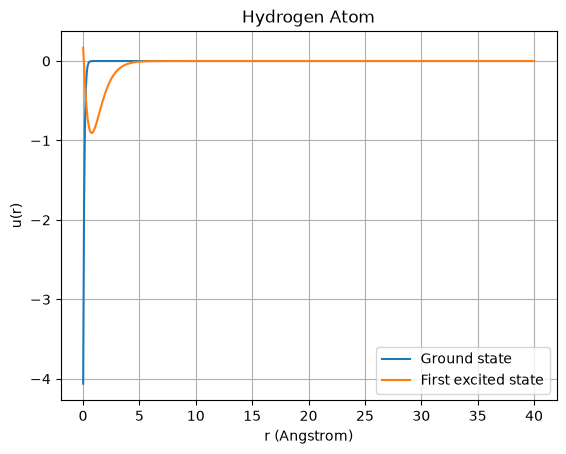

In [5]:

import numpy as np
import matplotlib.pyplot as plt

e = 3.795
hbar = 1973
m = 0.511e6

h = hbar**2/(2*m)

N = 500
r = np.linspace(0.01, 40, N)
dr = r[1]-r[0]

V = -e**2/r

H = np.diag(2*h/dr**2 + V)
H += np.diag(-h/dr**2*np.ones(N-1), 1)
H += np.diag(-h/dr**2*np.ones(N-1), -1)

E, psi = np.linalg.eigh(H)

print("Ground state energy =", E[0], "eV")
print("First excited energy =", E[1], "eV")

print("Analytical energies: -13.6 eV, -3.4 eV")

u1 = psi[:,0]
u2 = psi[:,1]

u1 = u1/np.sqrt(np.trapezoid(u1**2, r))
u2 = u2/np.sqrt(np.trapezoid(u2**2, r))

plt.plot(r,u1,label="Ground state")
plt.plot(r,u2,label="First excited state")

plt.xlabel("r (Angstrom)")
plt.ylabel("u(r)")
plt.title("Hydrogen Atom")
plt.legend()
plt.grid()
plt.show()





Screening length = 3 Angstrom
Ground state energy = -520.625 eV
Screening length = 5 Angstrom
Ground state energy = -522.53 eV
Screening length = 7 Angstrom
Ground state energy = -523.349 eV


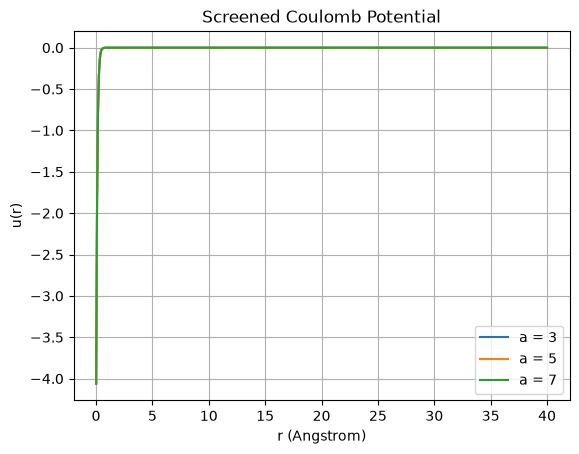

In [6]:

import numpy as np
import matplotlib.pyplot as plt

e = 3.795
hbar = 1973
m = 0.511e6

h = hbar**2/(2*m)

N = 500
r = np.linspace(0.01, 40, N)
dr = r[1]-r[0]

for a in [3, 5, 7]:

    V = -e**2/r * np.exp(-r/a)

    H = np.diag(2*h/dr**2 + V)
    H += np.diag(-h/dr**2*np.ones(N-1), 1)
    H += np.diag(-h/dr**2*np.ones(N-1), -1)

    E, psi = np.linalg.eigh(H)

    print("Screening length =", a, "Angstrom")
    print("Ground state energy =", round(E[0], 3), "eV")

    u = psi[:, 0]
    u = u/np.sqrt(np.trapezoid(u**2, r))

    plt.plot(r, u, label="a = "+str(a))

plt.xlabel("r (Angstrom)")
plt.ylabel("u(r)")
plt.title("Screened Coulomb Potential")
plt.legend()
plt.grid()
plt.show()
